# 06 — Fotos propias: etiquetas, segmentación por fondo y tamaño relativo

**Fase CRISP-DM:** preparación de los datos (conjunto de prueba externo).

Revisa las 18 fotos del equipo (`data/propias/`): cuántas hay por fruta y calidad, cómo funciona la segmentación sobre los dos fondos usados (base blanca lisa y toalla de papel con relieve) y qué tamaño relativo les asigna `src/data/tamano.py`. Aquí no se evalúa ningún modelo; eso corresponde a la evaluación externa.

In [1]:
import sys, os
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
os.environ["PYTHONPATH"] = str(RAIZ)

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import CALIDADES, FRUTAS_PROYECTO, RESULTADOS
from src.data.propias import cargar_etiquetas_propias, cargar_umbrales
from src.data.recortes import leer_bgr, recorte_cuadrado
from src.data.segmentacion import color_fondo, mascara_binaria, mascara_fruta
from src.data.tamano import estimar_tamano
from src.utils.visualizacion import estilo, guardar_figura

estilo()
et = cargar_etiquetas_propias()
et["fondo"] = np.where(et["notas"].str.contains("toalla"), "toalla de papel", "base blanca")
et["dano_provocado"] = et["notas"].str.contains("provocado")
print(f"{len(et)} fotos")
pd.crosstab([et["fruta"], et["calidad"]], et["fondo"], margins=True)

18 fotos


fondo            base blanca  toalla de papel  All
fruta   calidad                                   
banano  buena              2                0    2
        mala               0                2    2
        regular            2                0    2
manzana buena              2                0    2
        mala               1                1    2
        regular            1                1    2
naranja buena              2                0    2
        mala               0                2    2
        regular            2                0    2
All                       12                6   18

## 1. Características de las fotos

Las fotos se recortaron o redimensionaron antes de llegar al repositorio y no tienen EXIF; `scripts/preparar_fotos.py` las dejó con el lado mayor en 1024 px. Por eso no comparten distancia de cámara ni escala, y no hay diámetro medido en cm (`diametro_cm` vacío).

In [2]:
et["alto"], et["ancho"] = zip(*[leer_bgr(r).shape[:2] for r in et["ruta"]])
et[["archivo", "fruta", "calidad", "fondo", "ancho", "alto", "dano_provocado", "notas"]]

,archivo,fruta,calidad,fondo,ancho,alto,dano_provocado,notas
0,jjl_banano_01.jpg,banano,buena,base blanca,1024,928,False,sin_escala; fondo blanco; tamano relativo (umb...
1,jjl_banano_02.jpg,banano,buena,base blanca,1024,1001,False,sin_escala; fondo blanco; tamano relativo (umb...
2,jjl_banano_03.jpg,banano,regular,base blanca,1024,1002,False,sin_escala; fondo blanco; rayas oscuras de gol...
3,jjl_banano_04.jpg,banano,regular,base blanca,991,1024,False,sin_escala; fondo blanco; manchas cafés; taman...
4,jjl_banano_05.jpg,banano,mala,toalla de papel,576,1024,False,"sin_escala; toalla de papel; sobremaduro, cásc..."
5,jjl_banano_06.jpg,banano,mala,toalla de papel,576,1024,False,"sin_escala; toalla de papel; sobremaduro, cásc..."
6,jjl_manzana_01.jpg,manzana,buena,base blanca,1024,1002,False,sin_escala; fondo blanco; tamano relativo (umb...
7,jjl_manzana_02.jpg,manzana,buena,base blanca,984,1024,False,sin_escala; fondo blanco; tamano relativo (umb...
8,jjl_manzana_03.jpg,manzana,regular,toalla de papel,577,1024,False,sin_escala; toalla de papel; grieta y golpes c...
9,jjl_manzana_04.jpg,manzana,regular,base blanca,1024,985,False,sin_escala; fondo blanco; golpe café y zonas m...


## 2. Segmentación sobre cada fondo

Se usa el mismo pipeline de los modelos (`mascara_fruta`: Otsu sobre la distancia de color al fondo, refinado con GrabCut, más el respaldo de Otsu). Para cada foto se registran:
- **área relativa** de la máscara;
- si la máscara **toca el borde** de la imagen;
- número de **componentes** grandes (> 1 % de la imagen) antes de quedarse con el mayor;
- **solidez** (área / área de la envolvente convexa), que baja si la máscara tiene entrantes o se pega a una sombra;
- **contraste fruta–fondo**: distancia de color media ($\Delta E$ en la escala de 8 bits de CIELab de OpenCV) entre la fruta y el color de fondo estimado en el borde.

In [3]:
filas, vis = [], []
for _, r in et.iterrows():
    img = leer_bgr(r["ruta"])
    h, w = img.shape[:2]
    mb = mascara_binaria(img)
    n, _, st, _ = cv2.connectedComponentsWithStats(mb)
    m = mascara_fruta(img)
    x, y, bw, bh = cv2.boundingRect(m)
    cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    c = max(cs, key=cv2.contourArea)
    solidez = cv2.contourArea(c) / max(cv2.contourArea(cv2.convexHull(c)), 1)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB).astype(np.float32)
    fondo = color_fondo(lab)
    contraste = float(np.linalg.norm(lab[m > 0] - fondo, axis=1).mean())
    t = estimar_tamano(m)
    filas.append({"archivo": r["archivo"], "fondo": r["fondo"],
                  "area_rel": t["area_px"] / m.size,
                  "toca_borde": bool(x == 0 or y == 0 or x + bw == w or y + bh == h),
                  "componentes": int((st[1:, cv2.CC_STAT_AREA] > 0.01 * h * w).sum()),
                  "solidez": solidez, "contraste_fondo": contraste})
    vis.append((img, m))
seg = pd.DataFrame(filas)
seg.round(3)

,archivo,fondo,area_rel,toca_borde,componentes,solidez,contraste_fondo
0,jjl_banano_01.jpg,base blanca,0.203,False,1,0.659,79.070
1,jjl_banano_02.jpg,base blanca,0.177,False,1,0.681,76.527
2,jjl_banano_03.jpg,base blanca,0.175,False,1,0.641,84.630
3,jjl_banano_04.jpg,base blanca,0.171,False,1,0.709,78.511
4,jjl_banano_05.jpg,toalla de papel,0.173,False,1,0.833,130.603
5,jjl_banano_06.jpg,toalla de papel,0.161,False,1,0.789,129.264
6,jjl_manzana_01.jpg,base blanca,0.112,False,1,0.984,112.321
7,jjl_manzana_02.jpg,base blanca,0.117,False,1,0.986,113.067
8,jjl_manzana_03.jpg,toalla de papel,0.117,False,1,0.983,113.099
9,jjl_manzana_04.jpg,base blanca,0.119,False,1,0.984,125.031


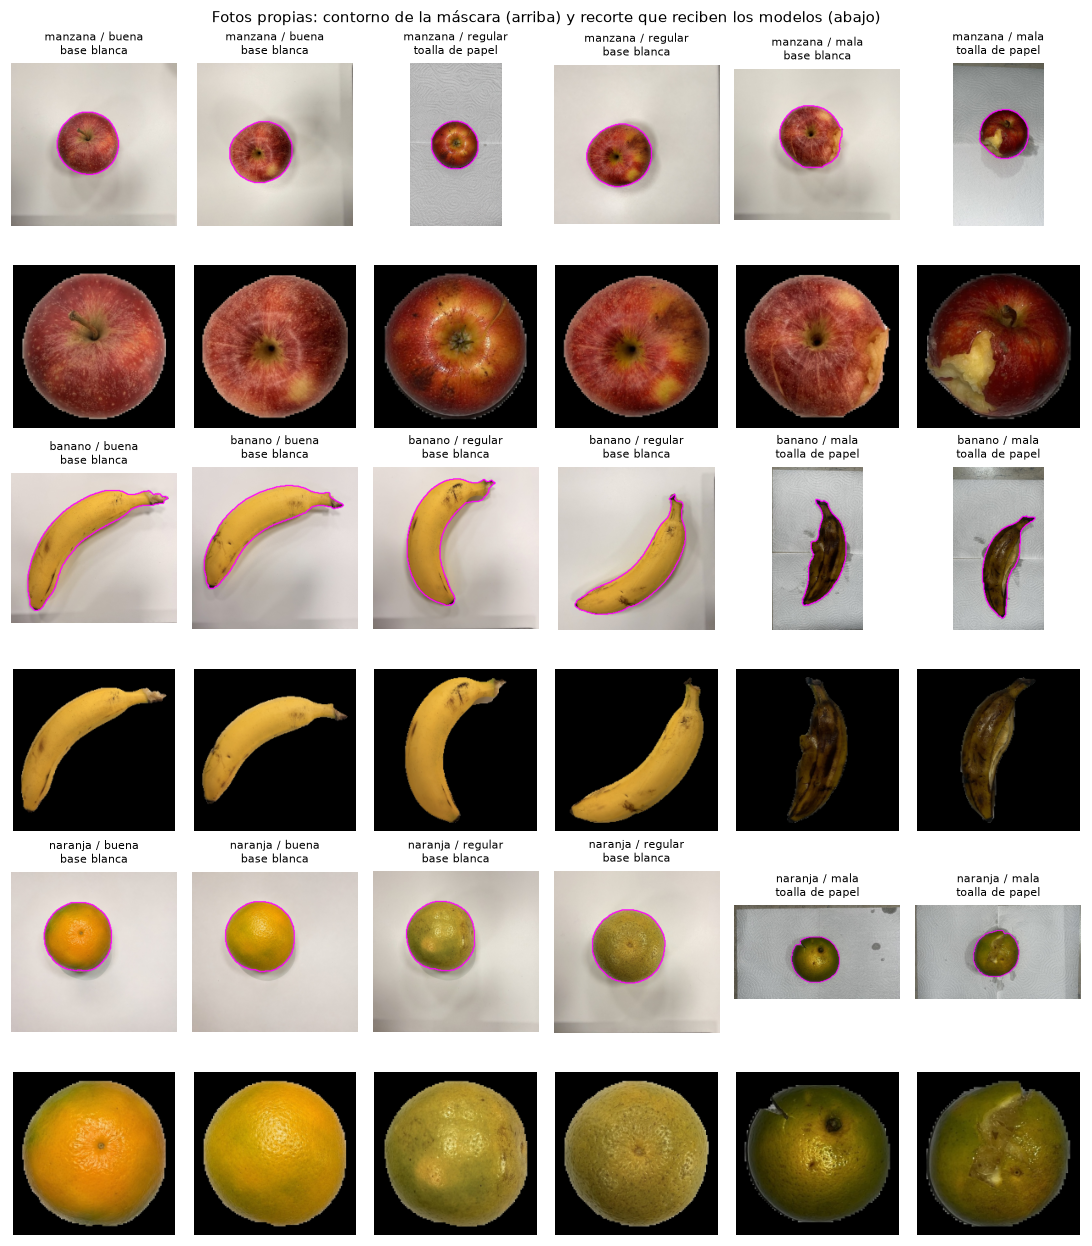

In [4]:
fig, axes = plt.subplots(6, 6, figsize=(10, 11.5))
orden = et.sort_values(["fruta", "calidad"], key=lambda s: s.map(
    {**{f: i for i, f in enumerate(FRUTAS_PROYECTO)}, **{c: i for i, c in enumerate(CALIDADES)}})).index
for k, i in enumerate(orden):
    img, m = vis[i]
    ax_f, ax_r = axes[(k // 6) * 2, k % 6], axes[(k // 6) * 2 + 1, k % 6]
    over = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).copy()
    cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(over, cs, -1, (255, 0, 255), max(2, img.shape[0] // 150))
    ax_f.imshow(over)
    rec, _ = recorte_cuadrado(img, m)
    ax_r.imshow(cv2.cvtColor(rec, cv2.COLOR_BGR2RGB))
    r = et.loc[i]
    ax_f.set_title(f"{r['fruta']} / {r['calidad']}\n{r['fondo']}", fontsize=7)
    for ax in (ax_f, ax_r):
        ax.axis("off")
fig.suptitle("Fotos propias: contorno de la máscara (arriba) y recorte que reciben los modelos (abajo)", fontsize=10)
fig.tight_layout()
guardar_figura(fig, "propias_segmentacion", raster=True, formatos=("png", "pdf"))
plt.show()

In [5]:
resumen = seg.groupby("fondo").agg(fotos=("archivo", "size"), area_rel=("area_rel", "median"),
                                    solidez=("solidez", "median"), contraste_fondo=("contraste_fondo", "median"),
                                    tocan_borde=("toca_borde", "sum"),
                                    con_varios_componentes=("componentes", lambda s: int((s > 1).sum())))
resumen.round(3).to_csv(RESULTADOS / "propias_segmentacion_por_fondo.csv")
seg.round(4).to_csv(RESULTADOS / "propias_segmentacion.csv", index=False)
resumen.round(3)

,fotos,area_rel,solidez,contraste_fondo,tocan_borde,con_varios_componentes
fondo,,,,,,
base blanca,12,0.143,0.984,87.071,0,0
toalla de papel,6,0.121,0.978,121.182,0,0


**Resultado por fondo.**
- **Base blanca lisa (12 fotos):** las 12 máscaras son correctas en la inspección visual. Ninguna toca el borde ni se partió en varios componentes. La solidez mediana es de 0,98 en manzana y naranja; en banano baja a 0,64–0,71 por la curvatura de la fruta, no por errores. Las sombras suaves bajo la fruta quedan fuera de la máscara. La franja gris que aparece en el borde inferior de algunas fotos (el canto de la mesa) no afectó la estimación del color de fondo.
- **Toalla de papel con relieve (6 fotos):** las 6 máscaras también son correctas. La textura del relieve, los pliegues y las manchas de humedad no aparecen en la máscara porque su color es casi el del fondo y la distancia de color al fondo es baja. El contraste fruta–fondo es incluso mayor que en la base blanca (mediana 121 contra 87) sobre todo por los bananos sobremaduros, que son mucho más oscuros que los amarillos de la base blanca.
- **Defectos dentro de la máscara:** la mordida, la piel arrancada de la manzana, la cáscara rasgada del banano y las aberturas de las naranjas quedan dentro del contorno, así que el recorte que reciben los modelos conserva el daño. Era un riesgo, porque la pulpa clara se parece al fondo blanco.

Las 18 fotos pasan los filtros automáticos de la preparación (área entre 2 % y 98 %, sin tocar el borde), así que todas sirven para la evaluación externa. Con solo 18 fotos y dos fondos, esto muestra que la segmentación funciona en condiciones controladas, no que sea robusta en general.

## 3. Tamaño relativo

El tamaño se clasifica en pequeño, mediano o grande con los percentiles 33 y 66 del diámetro normalizado $d / \max(H, W)$ del dataset (`experiments/results/umbrales_tamano.json`). Este valor depende de cuánto ocupa la fruta en el encuadre, y aquí cada foto tiene un encuadre distinto.

In [6]:
umbrales = cargar_umbrales()
tam = et[["archivo", "fruta", "calidad", "fondo", "tamano"]].merge(seg[["archivo", "area_rel"]], on="archivo")
tam["diametro_norm"] = [estimar_tamano(m)["diametro_norm"] for _, m in vis]
tam["p33"] = tam["fruta"].map(lambda f: umbrales[f][0])
tam["p66"] = tam["fruta"].map(lambda f: umbrales[f][1])
tam.round(3)

,archivo,fruta,calidad,fondo,tamano,area_rel,diametro_norm,p33,p66
0,jjl_banano_01.jpg,banano,buena,base blanca,mediano,0.203,0.484,0.418,0.531
1,jjl_banano_02.jpg,banano,buena,base blanca,mediano,0.177,0.470,0.418,0.531
2,jjl_banano_03.jpg,banano,regular,base blanca,mediano,0.175,0.467,0.418,0.531
3,jjl_banano_04.jpg,banano,regular,base blanca,mediano,0.171,0.459,0.418,0.531
4,jjl_banano_05.jpg,banano,mala,toalla de papel,pequeno,0.173,0.352,0.418,0.531
5,jjl_banano_06.jpg,banano,mala,toalla de papel,pequeno,0.161,0.340,0.418,0.531
6,jjl_manzana_01.jpg,manzana,buena,base blanca,pequeno,0.112,0.373,0.431,0.557
7,jjl_manzana_02.jpg,manzana,buena,base blanca,pequeno,0.117,0.379,0.431,0.557
8,jjl_manzana_03.jpg,manzana,regular,toalla de papel,pequeno,0.117,0.290,0.431,0.557
9,jjl_manzana_04.jpg,manzana,regular,base blanca,pequeno,0.119,0.382,0.431,0.557


**Lectura.** 14 de las 18 fotos quedan como "pequeño" y las otras 4 como "mediano" (los cuatro bananos de base blanca). No es que las frutas sean pequeñas: el diámetro normalizado mide qué fracción del encuadre ocupa la fruta, y cada foto se recortó o redimensionó a mano antes de llegar al repositorio. Por ejemplo, las naranjas malas sobre la toalla ocupan menos del encuadre y quedan con $d \approx 0{,}28$, contra 0,41–0,44 de las demás.

Por eso la columna `tamano` de `etiquetas.csv` está marcada como relativa en `notas`. Sirve para probar el flujo de la app, no para validar el estimador de tamaño. Para validarlo hacen falta fotos originales a distancia fija con el diámetro medido en cm (ver `docs/protocolo_fotos.md`).